## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('../data/ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

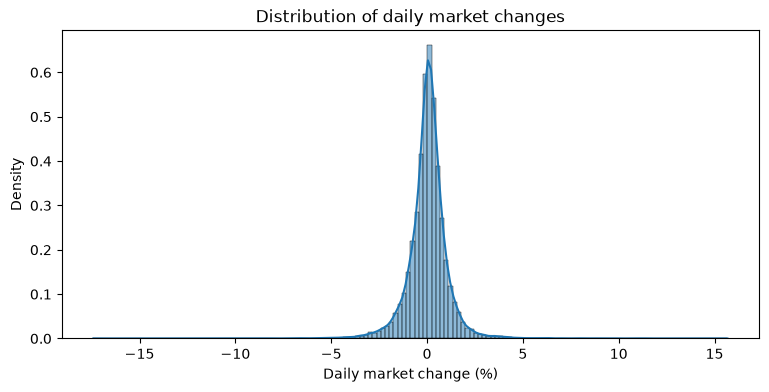

In [2]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

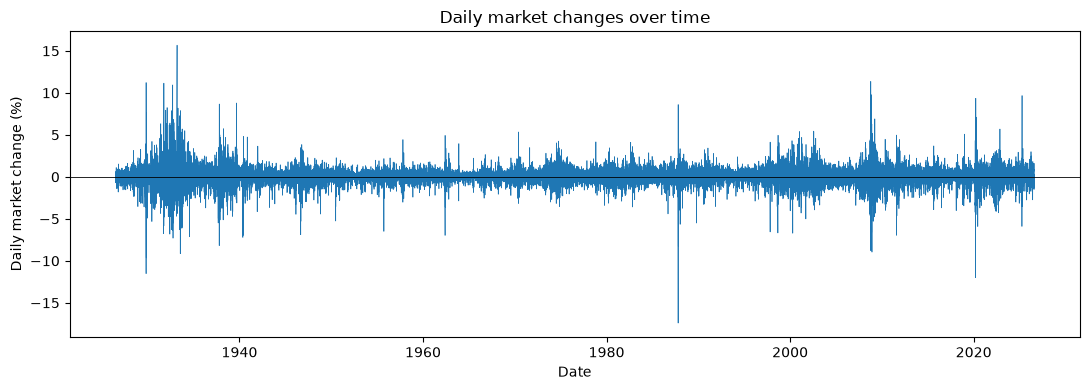

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

### Bullet 1

In [4]:
df['y'] = np.where(df['market_return_pct'] > 0, 'Up', 'Down')
df[['market_return_pct', 'y']]

,market_return_pct,y
0,0.10,Up
1,0.46,Up
2,0.18,Up
3,0.10,Up
4,0.23,Up
...,...,...
26291,0.17,Up
26292,0.29,Up
26293,-1.50,Down
26294,1.61,Up


In [5]:
df['y_1'] = df['y'].shift(-1)
df[['market_return_pct', 'y', 'y_1']]

,market_return_pct,y,y_1
0,0.10,Up,Up
1,0.46,Up,Up
2,0.18,Up,Up
3,0.10,Up,Up
4,0.23,Up,Down
...,...,...,...
26291,0.17,Up,Up
26292,0.29,Up,Down
26293,-1.50,Down,Up
26294,1.61,Up,Up


### Bullet 2

In [6]:
# cross tabulation:
pd.crosstab(df['y'], df['y_1'])

y_1,Down,Up
y,,
Down,5909,5999
Up,5999,8388


In [7]:
# joint pmf
joint_tab = pd.crosstab(df['y'], df['y_1'], normalize = True)
joint_tab

y_1,Down,Up
y,,
Down,0.224720,0.228142
Up,0.228142,0.318996


In [8]:
# conditional pmf:
cond_tab = pd.crosstab(df['y'], df['y_1'], normalize = 'index')
cond_tab

y_1,Down,Up
y,,
Down,0.496221,0.503779
Up,0.416974,0.583026


### Bullet 3
Are up transitions more or less common than down transitions?   
Down to Up transition is 0.228142. The Up to Down transition is also 0.228142. The Up transition and Down transition are equally common. The total of transitioning from Down to Down and Up to Down is less than the total of transitioning from Down to Up and Up to Up, so it is more common to transition Up than transition Down.

### Bullet 4
Are you more likely to transition to an Up day from a Down or Up day?  
You are more likely to transition to an Up day from an Up day (0.583026) than a Down day (0.503779).

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

### Bullet 1

In [9]:
df['mrkt_pct_bin'] = pd.cut(
    df['market_return_pct'],
    bins = [-np.inf, -1, -0.1, 0.1, 1, np.inf],
    labels = ['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']
    )

df['y0'] = df['mrkt_pct_bin']
df['y0_1'] = df['mrkt_pct_bin'].shift(-1)

In [10]:
df

,date,year,month,month_start,trading_day_of_month,mkt_excess_return_pct,risk_free_return_pct,market_return_pct,absolute_market_return_pct,y,y_1,mrkt_pct_bin,y0,y0_1
0,1926-07-01,1926,7,1926-07-01,1,0.09,0.01,0.10,0.10,Up,Up,Near zero,Near zero,Small gain
1,1926-07-02,1926,7,1926-07-01,2,0.45,0.01,0.46,0.46,Up,Up,Small gain,Small gain,Small gain
2,1926-07-06,1926,7,1926-07-01,3,0.17,0.01,0.18,0.18,Up,Up,Small gain,Small gain,Near zero
3,1926-07-07,1926,7,1926-07-01,4,0.09,0.01,0.10,0.10,Up,Up,Near zero,Near zero,Small gain
4,1926-07-08,1926,7,1926-07-01,5,0.22,0.01,0.23,0.23,Up,Down,Small gain,Small gain,Small loss
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26291,2026-07-27,2026,7,2026-07-01,18,0.15,0.02,0.17,0.17,Up,Up,Small gain,Small gain,Small gain
26292,2026-07-28,2026,7,2026-07-01,19,0.27,0.02,0.29,0.29,Up,Down,Small gain,Small gain,Large loss
26293,2026-07-29,2026,7,2026-07-01,20,-1.52,0.02,-1.50,1.50,Down,Up,Large loss,Large loss,Large gain
26294,2026-07-30,2026,7,2026-07-01,21,1.59,0.02,1.61,1.61,Up,Up,Large gain,Large gain,Small gain


How Many Days Fall Into each of the Bins?  
Most common days: small gain  
Least common days: Large loss 

In [11]:
df['y0'].value_counts()

y0
Small gain    9785
Small loss    7452
Near zero     3441
Large gain    2859
Large loss    2759
Name: count, dtype: int64

### Bullet 2

In [12]:
# joint PMF
joint_tab = pd.crosstab(df['y0'], df['y0_1'], normalize = True)
joint_tab

y0_1,Large loss,Small loss,Near zero,Small gain,Large gain
y0,,,,,
Large loss,0.021335,0.027191,0.009051,0.027800,0.019547
Small loss,0.035444,0.088648,0.034151,0.097775,0.027382
Near zero,0.009317,0.041985,0.020955,0.049325,0.009279
Small gain,0.024986,0.100057,0.055029,0.159422,0.032592
Large gain,0.013843,0.025518,0.011637,0.037802,0.019928


The transitions most likely to occur for the joint PMF is transitioning from a small gain to another small gain (0.159422) and transitioning from a small gain to a small loss (0.100057).

In [13]:
# marginals
marg_tab = pd.crosstab(df['y0'], df['y0_1'], normalize = True, margins = True)
marg_tab

y0_1,Large loss,Small loss,Near zero,Small gain,Large gain,All
y0,,,,,,
Large loss,0.021335,0.027191,0.009051,0.027800,0.019547,0.104925
Small loss,0.035444,0.088648,0.034151,0.097775,0.027382,0.283400
Near zero,0.009317,0.041985,0.020955,0.049325,0.009279,0.130861
Small gain,0.024986,0.100057,0.055029,0.159422,0.032592,0.372086
Large gain,0.013843,0.025518,0.011637,0.037802,0.019928,0.108728
All,0.104925,0.283400,0.130823,0.372124,0.108728,1.000000


<b>Which transitions are most likely to occur? </b>  
A Small gain (0.372086) and a small loss (0.283400) are the most likely transitions to occur. 

### Bullet 3
For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?

In [14]:
cond_tab = pd.crosstab(df['y0'], df['y0_1'], normalize = 'index')
cond_tab

y0_1,Large loss,Small loss,Near zero,Small gain,Large gain
y0,,,,,
Large loss,0.203335,0.259152,0.086263,0.264951,0.186299
Small loss,0.125067,0.312802,0.120505,0.345008,0.096618
Near zero,0.071200,0.320837,0.160128,0.376925,0.070910
Small gain,0.067150,0.268908,0.147895,0.428455,0.087592
Large gain,0.127317,0.234697,0.107030,0.347674,0.183281


<b>current state --> likely future states  </b>  
large loss - small gain, small loss  
small loss - small gain, small loss  
near zero - small gain, small loss  
small gain - small gain, small loss  
large gain - small gain, small loss  

I think rows large gain and large loss are roughly close to a uniform mass function with probability of 0.2. For instance, Large gain has probabilities .12, .23, .10, .34, and .18 while large loss has .20, .25, .086, .264, and .18. The other 3 rows, small loss, near zero, and small gain, are less uniform, but their probabilities are still very close in general. 

It is relatively difficult to predict the next state because none of the probabilities are large enough to confidently distinguish one state being clearly more likely than the other. 

### Bullet 4
For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [15]:
df['mkt_pct_1'] = df['market_return_pct'].shift(-1)
df.groupby('y0', observed=False)['mkt_pct_1'].describe()

,count,mean,std,min,25%,50%,75%,max
y0,,,,,,,,
Large loss,2759.0,-0.038311,1.720570,-17.41,-0.79,-0.01,0.72,11.22
Small loss,7452.0,-0.043814,1.009529,-11.23,-0.53,0.01,0.45,11.36
Near zero,3441.0,0.015013,0.826054,-8.19,-0.35,0.03,0.42,5.49
Small gain,9784.0,0.106810,0.832186,-8.25,-0.25,0.12,0.50,8.67
Large gain,2859.0,0.163092,1.384086,-12.00,-0.37,0.15,0.73,15.67


<b>Expected percent returns for tomorrow given current state </b>  
large loss = -0.038311  
small loss = -0.043814  
near zero = 0.015013  
small gain = 0.106810  
large gain = 0.163092  

<b> How do min and max values for tomorrow vary across states </b>  
The min values for the 5 states range from -8.25 to -17.41. The max values for the 5 states range from 5.49 to 15.67.  
<b>Which states have the highest standard deviation for tomorrow's percent return</b>  
Large loss (1.720570), large gain (1.384086) and small loss (1.009529).  
<b>volatility</b>  
The states that have the largest standard deviations have the lowest mins and the highest max while the states that have lower and similar standard deviations have mins and maxes that are not as large. 

### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

### Bullet 1

In [16]:
df['y_t'] = pd.qcut(df['market_return_pct'], 21, labels=False)
df['y_tp1'] = df['y_t'].shift(-1)
df

,date,year,month,month_start,trading_day_of_month,mkt_excess_return_pct,risk_free_return_pct,market_return_pct,absolute_market_return_pct,y,y_1,mrkt_pct_bin,y0,y0_1,mkt_pct_1,y_t,y_tp1
0,1926-07-01,1926,7,1926-07-01,1,0.09,0.01,0.10,0.10,Up,Up,Near zero,Near zero,Small gain,0.46,10,15.0
1,1926-07-02,1926,7,1926-07-01,2,0.45,0.01,0.46,0.46,Up,Up,Small gain,Small gain,Small gain,0.18,15,11.0
2,1926-07-06,1926,7,1926-07-01,3,0.17,0.01,0.18,0.18,Up,Up,Small gain,Small gain,Near zero,0.10,11,10.0
3,1926-07-07,1926,7,1926-07-01,4,0.09,0.01,0.10,0.10,Up,Up,Near zero,Near zero,Small gain,0.23,10,12.0
4,1926-07-08,1926,7,1926-07-01,5,0.22,0.01,0.23,0.23,Up,Down,Small gain,Small gain,Small loss,-0.70,12,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26291,2026-07-27,2026,7,2026-07-01,18,0.15,0.02,0.17,0.17,Up,Up,Small gain,Small gain,Small gain,0.29,11,13.0
26292,2026-07-28,2026,7,2026-07-01,19,0.27,0.02,0.29,0.29,Up,Down,Small gain,Small gain,Large loss,-1.50,13,1.0
26293,2026-07-29,2026,7,2026-07-01,20,-1.52,0.02,-1.50,1.50,Down,Up,Large loss,Large loss,Large gain,1.61,1,20.0
26294,2026-07-30,2026,7,2026-07-01,21,1.59,0.02,1.61,1.61,Up,Up,Large gain,Large gain,Small gain,0.70,20,17.0


In [17]:
help(pd.qcut)

Help on function qcut in module pandas:

qcut(
    x,
    q,
    labels=None,
    retbins: bool = False,
    precision: int = 3,
    duplicates: str = 'raise'
)
    Quantile-based discretization function.

    Discretize variable into equal-sized buckets based on rank or based
    on sample quantiles. For example 1000 values for 10 quantiles would
    produce a Categorical object indicating quantile membership for each data point.

    Parameters
    ----------
    x : 1d ndarray or Series
        Input Numpy array or pandas Series object to be discretized.
    q : int or list-like of float
        Number of quantiles. 10 for deciles, 4 for quartiles, etc. Alternately
        array of quantiles, e.g. [0, .25, .5, .75, 1.] for quartiles.
    labels : array or False, default None
        Used as labels for the resulting bins. Must be of the same length as
        the resulting bins. If False, return only integer indicators of the
        bins. If True, raises an error.
    retbins : bool

### Bullet 2
Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.

In [18]:
joint_tab = pd.crosstab(df['y_t'], df['y_tp1'], normalize = True)
joint_tab

y_tp1,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,...,11.0,12.0,13.0,14.0,15.0,16.0,17.0,18.0,19.0,20.0
y_t,,,,,,,,,,,,,,,,,,,,,
0,0.006959,0.003651,0.002928,0.001787,0.002206,0.001749,0.001825,0.001141,0.001369,0.001331,...,0.001027,0.001331,0.001331,0.001103,0.001597,0.001141,0.001940,0.002016,0.003613,0.006883
1,0.004868,0.003385,0.003195,0.002206,0.002320,0.001978,0.002206,0.001673,0.001445,0.002320,...,0.001559,0.001331,0.001521,0.001711,0.001597,0.001825,0.001825,0.002890,0.002510,0.003651
2,0.003651,0.003765,0.003727,0.003803,0.002244,0.001863,0.002130,0.001825,0.001483,0.002054,...,0.001978,0.002358,0.002244,0.001635,0.001369,0.002054,0.001825,0.002320,0.002510,0.002662
3,0.002814,0.003689,0.003080,0.002776,0.002700,0.002472,0.002358,0.001559,0.002130,0.002396,...,0.001787,0.001940,0.001521,0.002282,0.002130,0.002282,0.001787,0.002434,0.002548,0.002092
4,0.002320,0.002700,0.002890,0.002586,0.002130,0.002548,0.002624,0.002168,0.002320,0.001825,...,0.002054,0.001863,0.001749,0.002738,0.002168,0.001940,0.002662,0.001635,0.002282,0.001863
5,0.002054,0.002852,0.002510,0.002890,0.002738,0.002206,0.002282,0.002434,0.001940,0.002130,...,0.001863,0.002206,0.002092,0.001940,0.002054,0.002586,0.002624,0.001559,0.001940,0.001940
6,0.002396,0.002814,0.003347,0.003195,0.002814,0.002814,0.002206,0.002244,0.002434,0.002472,...,0.001940,0.002586,0.003195,0.002510,0.002130,0.002510,0.001940,0.001749,0.002396,0.001673
7,0.001521,0.002358,0.002434,0.003156,0.002168,0.002358,0.002776,0.002434,0.001902,0.002282,...,0.002358,0.002472,0.001863,0.002206,0.002206,0.001521,0.001940,0.001863,0.001978,0.001179
8,0.001331,0.002016,0.002434,0.002434,0.002510,0.002472,0.002320,0.002472,0.002358,0.002738,...,0.002472,0.002434,0.002206,0.002510,0.002358,0.001902,0.002130,0.001787,0.001445,0.001521


[Text(0.5, 1.0, 'Joint PMF')]

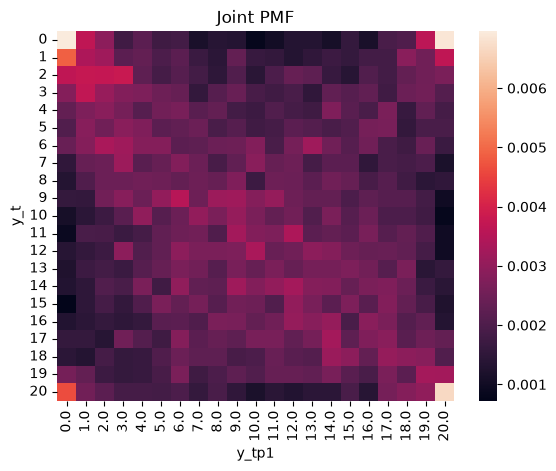

In [19]:
sns.heatmap(joint_tab).set(title='Joint PMF')

[Text(0.5, 1.0, 'Joint PMF')]

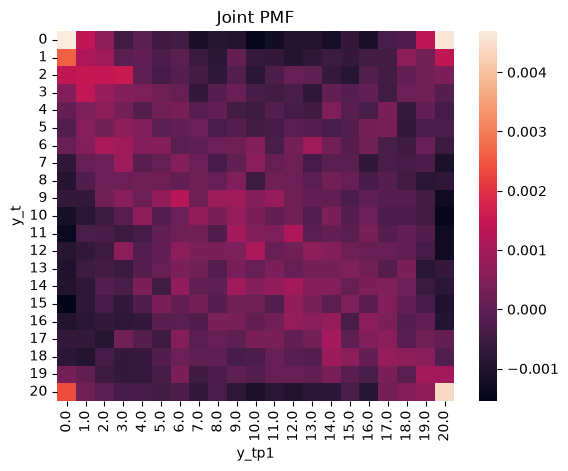

In [20]:
# normalize
joint_tab = joint_tab - (1/21**2)
sns.heatmap(joint_tab).set(title='Joint PMF')

<b>Obvious Patterns </b>  
The joint pmf has a higher probability of staying in its same state between the current day and the next day. As the state moves further from its current state, the probability decreases.

### Bullet 3
Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.

In [21]:
cond_tab = pd.crosstab(df['y_t'], df['y_tp1'], normalize = 'index')
cond_tab

y_tp1,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,...,11.0,12.0,13.0,14.0,15.0,16.0,17.0,18.0,19.0,20.0
y_t,,,,,,,,,,,,,,,,,,,,,
0,0.145817,0.076494,0.061355,0.037450,0.046215,0.036653,0.038247,0.023904,0.028685,0.027888,...,0.021514,0.027888,0.027888,0.023108,0.033466,0.023904,0.040637,0.042231,0.075697,0.144223
1,0.102155,0.071030,0.067039,0.046289,0.048683,0.041500,0.046289,0.035116,0.030327,0.048683,...,0.032721,0.027933,0.031923,0.035914,0.033520,0.038308,0.038308,0.060654,0.052674,0.076616
2,0.074650,0.076983,0.076205,0.077760,0.045879,0.038103,0.043546,0.037325,0.030327,0.041991,...,0.040435,0.048212,0.045879,0.033437,0.027994,0.041991,0.037325,0.047434,0.051322,0.054432
3,0.057813,0.075781,0.063281,0.057031,0.055469,0.050781,0.048438,0.032031,0.043750,0.049219,...,0.036719,0.039844,0.031250,0.046875,0.043750,0.046875,0.036719,0.050000,0.052344,0.042969
4,0.049593,0.057724,0.061789,0.055285,0.045528,0.054472,0.056098,0.046341,0.049593,0.039024,...,0.043902,0.039837,0.037398,0.058537,0.046341,0.041463,0.056911,0.034959,0.048780,0.039837
5,0.044046,0.061175,0.053834,0.061990,0.058728,0.047308,0.048940,0.052202,0.041599,0.045677,...,0.039967,0.047308,0.044861,0.041599,0.044046,0.055465,0.056281,0.033442,0.041599,0.041599
6,0.045952,0.053975,0.064187,0.061269,0.053975,0.053975,0.042305,0.043034,0.046681,0.047411,...,0.037199,0.049599,0.061269,0.048140,0.040846,0.048140,0.037199,0.033552,0.045952,0.032093
7,0.033167,0.051410,0.053068,0.068823,0.047264,0.051410,0.060531,0.053068,0.041459,0.049751,...,0.051410,0.053897,0.040630,0.048093,0.048093,0.033167,0.042289,0.040630,0.043118,0.025705
8,0.029215,0.044240,0.053422,0.053422,0.055092,0.054257,0.050918,0.054257,0.051753,0.060100,...,0.054257,0.053422,0.048414,0.055092,0.051753,0.041736,0.046745,0.039232,0.031720,0.033389


[Text(0.5, 1.0, 'Conditional PMF')]

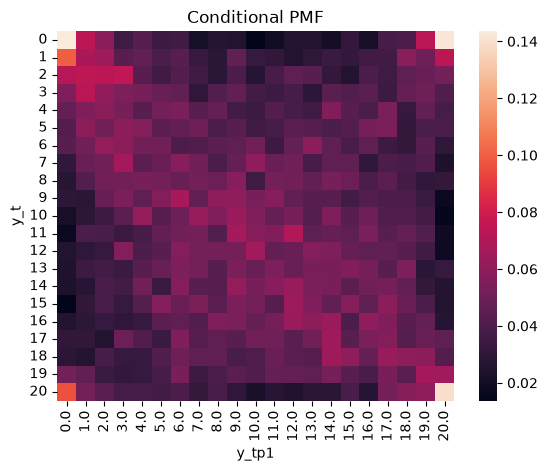

In [22]:
# normalize
cond_tab = cond_tab - (1/21**2)
sns.heatmap(cond_tab).set(title='Conditional PMF')

<b>Obvious Patterns</b>  
The conditional pmf has a higher probability of staying in its same state the next day given the state its current day. As the state moves further from its current state, the probability decreases.

### Bullet 4
For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 

In [23]:
df_describe = df.groupby('y_tp1', observed = False)['market_return_pct'].describe()

In [24]:
df_describe

,count,mean,std,min,25%,50%,75%,max
y_tp1,,,,,,,,
0.0,1255.0,-0.212932,1.790781,-11.23,-1.0500,-0.250,0.5000,10.94
1.0,1253.0,-0.148923,1.210205,-6.82,-0.7000,-0.150,0.3600,7.88
2.0,1286.0,-0.114401,1.167416,-7.36,-0.6075,-0.095,0.3600,11.36
3.0,1280.0,-0.051641,0.944585,-6.89,-0.4625,-0.050,0.3600,8.79
4.0,1230.0,-0.000285,0.966945,-4.46,-0.4075,0.020,0.4100,9.78
5.0,1226.0,0.027496,0.875515,-5.03,-0.3500,0.040,0.4700,3.98
6.0,1371.0,0.078658,0.890034,-5.90,-0.3200,0.090,0.5000,4.44
7.0,1206.0,0.097852,0.833132,-5.46,-0.2500,0.105,0.4800,7.10
8.0,1198.0,0.123164,0.863767,-4.67,-0.2600,0.100,0.5400,7.91


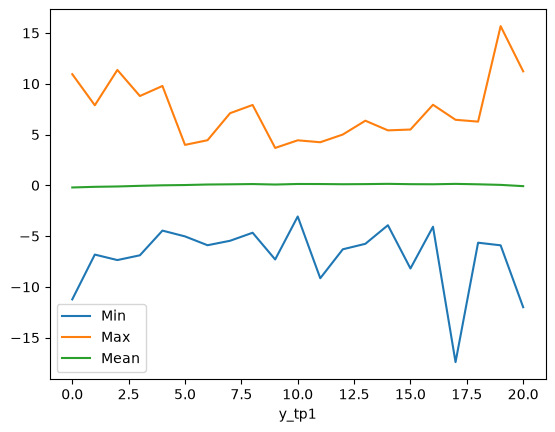

In [25]:
sns.lineplot(data=df_describe, x='y_tp1', y='min', label='Min')
sns.lineplot(data=df_describe, x='y_tp1', y='max', label='Max')
sns.lineplot(data=df_describe, x='y_tp1', y='mean', label='Mean')
plt.ylabel('')
plt.legend()

<b>Obvious Patterns</b>  
The mean between the different bins remains relatively constant around 0.   
The min values range from around 5 to 16, and they have random peaks and valleys.  
The max values range from around -15 to -4, and they also have random peaks and valleys.  
Between the min and the max values, you can have a small min and a small max in the same bin and vice versa. It does not same to follow a relationship of having a high max value and a low min value. 

### Bullet 5
For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 


In [26]:
df_describe['std']

y_tp1
0.0     1.790781
1.0     1.210205
2.0     1.167416
3.0     0.944585
4.0     0.966945
5.0     0.875515
6.0     0.890034
7.0     0.833132
8.0     0.863767
9.0     0.798587
10.0    0.741366
11.0    0.830258
12.0    0.815200
13.0    0.805602
14.0    0.786699
15.0    0.952284
16.0    0.833355
17.0    1.064121
18.0    1.010596
19.0    1.256697
20.0    2.045104
Name: std, dtype: float64

<Axes: xlabel='y_tp1', ylabel='std'>

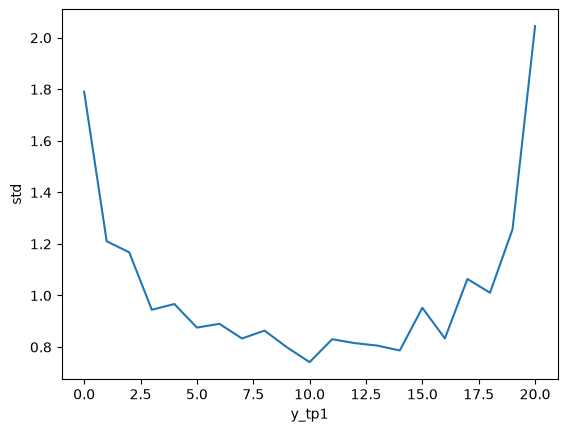

In [27]:
sns.lineplot(data=df_describe, x='y_tp1', y='std')

<b>Obvious Patterns </b>  
The edge of the bins, like bins close to bin 0 and bin 20, have higher standard deviations than the bins near the middle, like bin 10, which has the lowest standard deviation. The plot roughly outlines a positive parabola shape. 

In [28]:
help(sns.lineplot)

Help on function lineplot in module seaborn.relational:

lineplot(
    data=None,
    *,
    x=None,
    y=None,
    hue=None,
    size=None,
    style=None,
    units=None,
    weights=None,
    palette=None,
    hue_order=None,
    hue_norm=None,
    sizes=None,
    size_order=None,
    size_norm=None,
    dashes=True,
    markers=None,
    style_order=None,
    estimator='mean',
    errorbar=('ci', 95),
    n_boot=1000,
    seed=None,
    orient='x',
    sort=True,
    err_style='band',
    err_kws=None,
    legend='auto',
    ci='deprecated',
    ax=None,
    **kwargs
)
    Draw a line plot with possibility of several semantic groupings.

    The relationship between `x` and `y` can be shown for different subsets
    of the data using the `hue`, `size`, and `style` parameters. These
    parameters control what visual semantics are used to identify the different
    subsets. It is possible to show up to three dimensions independently by
    using all three semantic types, but this s

### Bullet 6
How easy is it to predict the market?

It is difficult to predict the market. From the intial Daily Market Changes Over Time plot, it was difficult to see a pattern between a large loss and a small gain and vice versa. The market could be performing well and poorly at the same time. When cross tabulating, there was a relatively uniform count of down to down, down to up, and up to down, with up and up being a common transition. After binning, it was common to see a small gain and a small loss, but there were no distinct probabilities that clearly stood out. The most obvious pattern was the state not moving from day to day or a small gain or loss happening, making it difficult to predict the market. 